# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
### Process training data

**Notebook by Alice DuVivier - April 2026**
- Loads Alaskan SOND data for the decades of interest that we already subset and prepare for SOM training dataset

In [1]:
from glob import glob
import xarray as xr
from datetime import datetime
import time
import cftime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta

# Regridding
import xesmf as xe

## Section 1: Load grid files and create re-gridding weights

In [2]:
# set input directory
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/'

### Load CAM elevation file

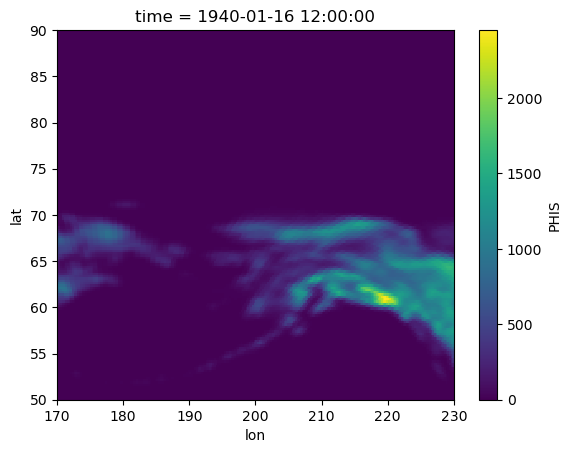

In [3]:
# load the land elevation file
fin = dir_in + 'MESACLIP_HGT_alaska.nc'
ds_hgt = xr.open_dataset(fin)

ds_hgt = ds_hgt.PHIS.isel(time=0)
ds_hgt.plot()

In [4]:
# reassign lon grid to be from -180 to 180 instead of 0-360
lon2 = np.where(ds_hgt.lon <180, ds_hgt.lon, ds_hgt.lon - 360)
ds_hgt['lon'] = lon2

In [5]:
# assign unit attributes
ds_hgt.lat.attrs['units'] = 'degrees_north'
ds_hgt.lon.attrs['units'] = 'degrees_east'

### Load EASE grid

In [6]:
# load the EASE grid
fin = dir_in + 'ease_nh50km_coordinates.nc'

ease_grid_full = xr.open_dataset(fin)
# replace missing values with nan
ease_grid_full = ease_grid_full.where(ease_grid_full != -999)

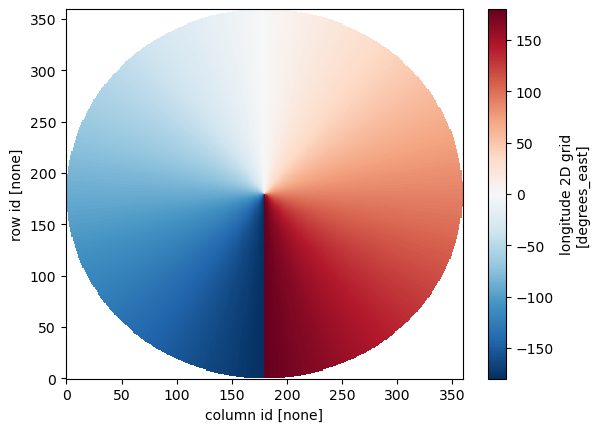

In [7]:
#ease_grid_full.lat2d.plot()
ease_grid_full.lon2d.plot()

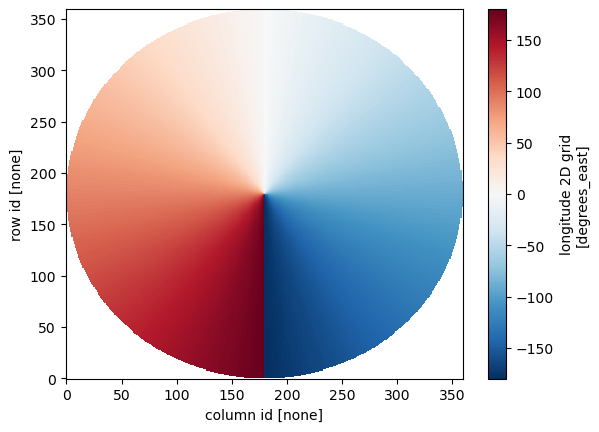

In [8]:
# this is a mirror image around -180/180, so need to reverse the column id values to match a normal map
test = -1 * ease_grid_full
#test.lon2d.plot()

# rewrite variable
ease_grid_full['lon2d'] = test['lon2d']
ease_grid_full.lon2d.plot()

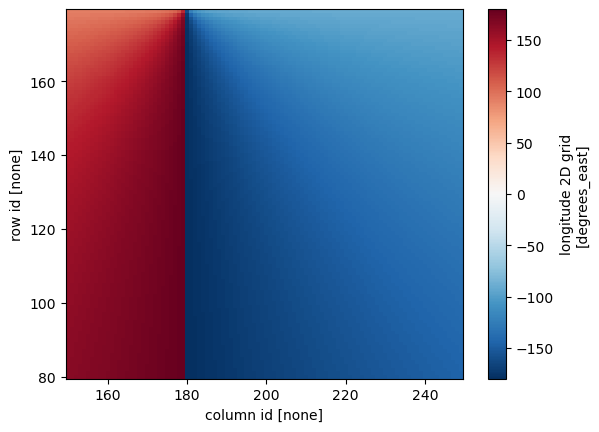

In [9]:
# subset ease grid
ease_grid_sub = ease_grid_full.isel(row=slice(80, 180),col=slice(150,250))
ease_grid_sub.lon2d.plot()

### Regrid

In [10]:
# set target and source grids
#lon_target, lat_target = ease_grid_full['lon2d'], ease_grid_full['lat2d']
lon_target, lat_target = ease_grid_sub['lon2d'], ease_grid_sub['lat2d']
lon_source, lat_source = ds_hgt['lon'], ds_hgt['lat']

In [11]:
# rename dimensions so that they make regridder happy
source_grid = {'lat': lat_source, 'lon': lon_source}
target_grid = {'lat': lat_target, 'lon': lon_target}

In [12]:
# actually regrid now
regridder = xe.Regridder(ds_hgt, target_grid, method='bilinear', unmapped_to_nan=True)
ds_hgt_regridded = regridder(ds_hgt)

/glade/u/apps/opt/miniforge/envs/npl-2026a/lib/python3.13/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not F_CONTIGUOUS. ' 'Will affect performance.')


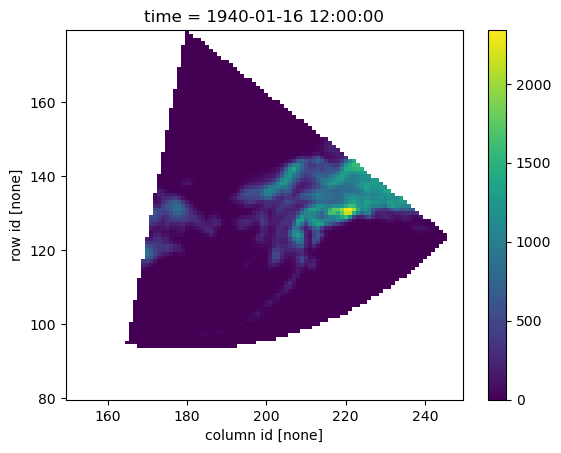

In [13]:
ds_hgt_regridded.plot()

## Section 2: Create Spatial Mask for Training Data
- Masks terrain above 500m - sea level pressure is weird over land so omit
- Crops to the training domain only (45-75N and 150-180W)

In [14]:
# make new array to match height
new = xr.ones_like(ds_hgt_regridded)
#new.plot()

In [15]:
ds_hgt_regridded

<xarray.DataArray (row: 100, col: 100)> Size: 80kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(100, 100))
Coordinates:
  * row      (row) float32 400B 80.0 81.0 82.0 83.0 ... 176.0 177.0 178.0 179.0
  * col      (col) float32 400B 150.0 151.0 152.0 153.0 ... 247.0 248.0 249.0
    time     object 8B 1940-01-16 12:00:00
    lat2d    (row, col) float32 40kB 41.65 41.79 41.92 ... 59.31 58.84 58.38
    lon2d    (row, col) float32 40kB 163.4 163.9 164.5 ... -90.64 -90.63 -90.62
Attributes:
    regrid_method:  bilinear

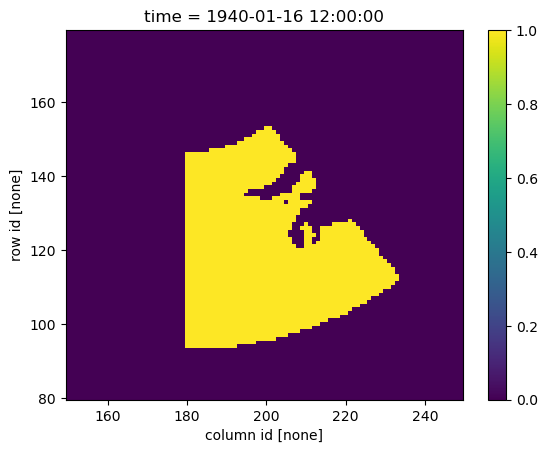

In [16]:
# need to use the intersection of masks for heights, lats, and lons we specify
ds_mask = xr.where((ds_hgt_regridded['lat2d']<75)&(ds_hgt_regridded['lat2d']>45)&(ds_hgt_regridded['lon2d']<-141)&(ds_hgt_regridded < 500),new,0)
ds_mask.plot()

## Section 3: Load Data and Regrid to EASE grid

In [17]:
# set input directory
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/'

In [18]:
# load the PSL file
fin = dir_in + 'psl_autumn_decadal_alaska_cam_grid.nc'
ds = xr.open_dataset(fin)
ds_psl = ds.psl

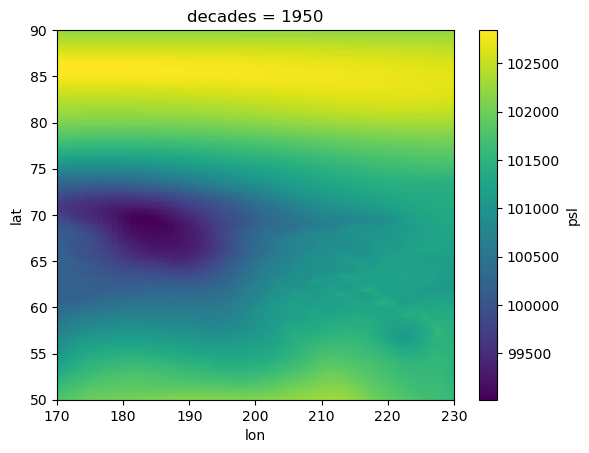

In [20]:
ds_psl.isel(ensemble=0,decades=0,autumn_days=0).plot()

### Regrid
- Target and source grids were specified above

In [21]:
# actually regrid now
regridder = xe.Regridder(ds_psl, target_grid, method='bilinear', unmapped_to_nan=True)
ds_psl_regridded = regridder(ds_psl)

/glade/u/apps/opt/miniforge/envs/npl-2026a/lib/python3.13/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not F_CONTIGUOUS. ' 'Will affect performance.')


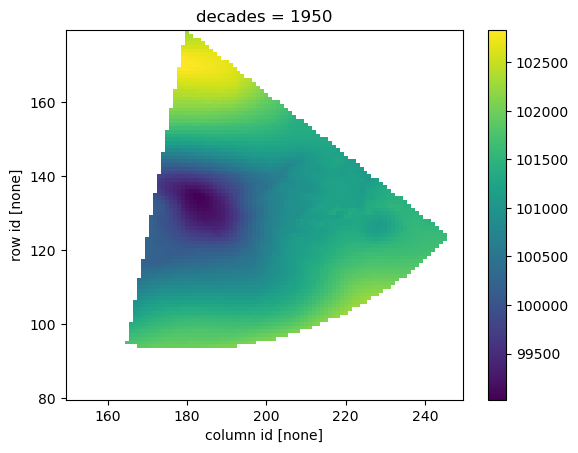

In [22]:
ds_psl_regridded.isel(ensemble=0,decades=0,autumn_days=0).plot()

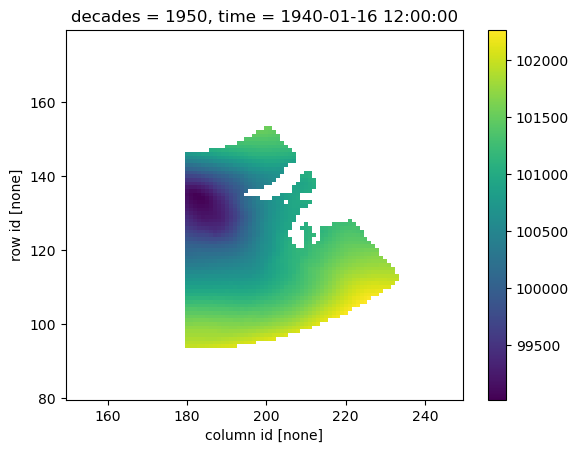

In [23]:
# quick test on the masking to see if it works as expected
test = ds_psl_regridded.where(ds_mask == 1)
test.isel(ensemble=0,decades=0,autumn_days=0).plot()

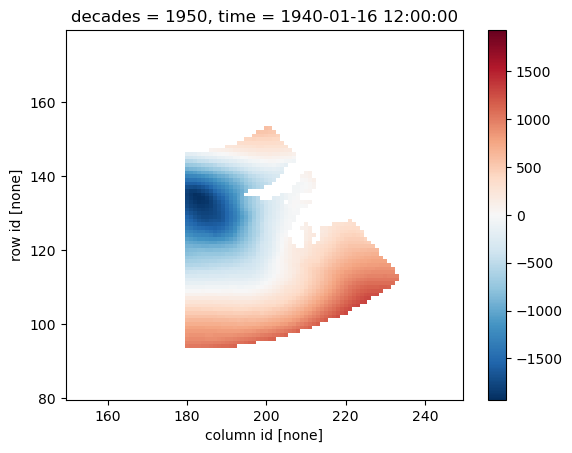

In [24]:
# quick test on the psl anomaly calculation to see if it works as expected
test2 = test.mean(dim=["row", "col"])
test3 = test - test2
test3.isel(ensemble=0,decades=0,autumn_days=0).plot()

## Section 4: Make into training array needed by MiniSOM
- Get daily 1D npts array (ntimes x npts) by stacking all dates (ntimes = ensemble x decades x autumn days) and all spatial points WITHIN the training mask (npts = col x row)
- Drop any Nans

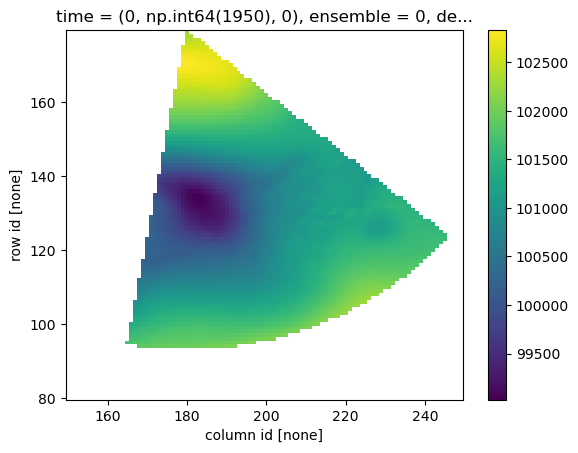

In [25]:
# stack all times into a single array
ds_psl_all_times = ds_psl_regridded.stack(time=("ensemble","decades","autumn_days"))
ds_psl_all_times.isel(time=0).plot()

In [26]:
# stack the mask for correct value dropping
mask_stacked = ds_mask.stack(horizontal=("row","col"))

# drop the time array so we can use this with the rest of the psl data
mask_stacked = mask_stacked.drop_vars("time")

mask_stacked

<xarray.DataArray (horizontal: 10000)> Size: 80kB
array([0., 0., 0., ..., 0., 0., 0.], shape=(10000,))
Coordinates:
  * horizontal  (horizontal) object 80kB MultiIndex
    lat2d       (horizontal) float32 40kB 41.65 41.79 41.92 ... 58.84 58.38
    lon2d       (horizontal) float32 40kB 163.4 163.9 164.5 ... -90.63 -90.62
  * row         (horizontal) float32 40kB 80.0 80.0 80.0 ... 179.0 179.0 179.0
  * col         (horizontal) float32 40kB 150.0 151.0 152.0 ... 248.0 249.0
Attributes:
    regrid_method:  bilinear

In [27]:
# stack data points horizontally
ds_psl_stacked = ds_psl_all_times.stack(horizontal=("row","col"))

In [28]:
# now drop points that are masked
ds_psl_masked = ds_psl_stacked.where(mask_stacked,drop=True)

In [29]:
# check the data dims/shape
print(ds_psl_masked.shape)
# confirm there are no NaN values in array for training (should print False if no values)
print(np.isnan(ds_psl_masked).any())

(49410, 2007)
<xarray.DataArray ()> Size: 1B
array(False)
Attributes:
    regrid_method:  bilinear


## Section 5: Calculate PSL anomalies
- Calculate daily PSL anomaly over the spatial domain for each day

In [30]:
# calculate daily means over the spatial domain
ds_psl_masked_mean = ds_psl_masked.mean(dim=["horizontal"])

In [31]:
# calculate daily anomalies using the daily means
ds_psl_masked_anom = ds_psl_masked - ds_psl_masked_mean

## Section 6: Prepare and Save Training Data

In [55]:
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/som_training/'

In [56]:
fout = 'mesaclip_training_data_alaska_psl_autumn_decadal.nc'

In [57]:
training_subset = ds_psl_masked_anom

In [58]:
# assign to numpy array object
subsetarray = training_subset.values

In [59]:
# triple check the data dims/shape
print(subsetarray.shape)
# confirm there are no NaN values in array for training (should print False if no values)
print(np.isnan(subsetarray).any())

(49410, 2007)
False


In [60]:
ds_to_save = xr.Dataset({'train_data': (['training_times','points'], subsetarray)}, 
                        coords={'ensemble':(['training_times'],training_subset.ensemble.values),
                                'decades':(['training_times'],training_subset.decades.values),
                                'autumn_days':(['training_times'],training_subset.autumn_days.values),
                                'lon2d':(['points'],training_subset.lon2d.values),
                                'lat2d':(['points'],training_subset.lat2d.values),
                                'row':(['points'],training_subset.row.values),
                                'col':(['points'],training_subset.col.values)},
                        attrs={'Author': 'Alice DuVivier'})

In [61]:
ds_to_save

<xarray.Dataset> Size: 795MB
Dimensions:      (training_times: 49410, points: 2007)
Coordinates:
    ensemble     (training_times) int64 395kB 0 0 0 0 0 0 0 0 ... 8 8 8 8 8 8 8
    decades      (training_times) int64 395kB 1950 1950 1950 ... 2090 2090 2090
    autumn_days  (training_times) int64 395kB 0 1 2 3 4 ... 361 362 363 364 365
    lon2d        (points) float32 8kB -179.8 -179.2 -178.5 ... -142.9 -141.5
    lat2d        (points) float32 8kB 50.56 50.56 50.55 ... 73.91 74.83 74.55
    row          (points) float32 8kB 94.0 94.0 94.0 94.0 ... 152.0 153.0 153.0
    col          (points) float32 8kB 180.0 181.0 182.0 ... 202.0 200.0 201.0
Dimensions without coordinates: training_times, points
Data variables:
    train_data   (training_times, points) float64 793MB 1.01e+03 ... 1.502e+03
Attributes:
    Author:   Alice DuVivier

In [62]:
# calculate the size of the dataset in GB
size_gb = ds_to_save.nbytes / (1024**3)
print(f"The dataset is approximately {size_gb:.2f} GB.")

The dataset is approximately 0.74 GB.


In [63]:
dir_out + fout

'/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/som_training/mesaclip_training_data_alaska_psl_autumn_decadal.nc'

In [65]:
print('Writing training_data_file')
ds_to_save.to_netcdf(dir_out + fout)  # how to save file

Writing training_data_file
